# EMQA_L4_coverage

**Widening the tails brings the 99% quantile close to its promise**

Energy Markets Quantitative Analysis (EMQA), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L4/EMQA_L4_coverage/EMQA_L4_coverage.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per zone / series


def legend_bottom(fig, ncol=4):
    # one legend for the whole figure, centred under the axes
    handles, labels = [], []
    for ax in fig.axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def show(key, value):
    # prints a number shown on the slide, under its key in lectures/L4/L4_numbers.json
    print(f'{key:<28} = {value}')


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
START = pd.Timestamp('2015-01-01')
END = pd.Timestamp('2026-10-31')           # cut-off of Lecture 4: last complete month of the download
CAL = pd.date_range(START, END, freq='D')
P = PD[['RO']].reindex(CAL)           # full calendar: missing days stay missing
X = P.diff()                           # daily change X_t = P_t - P_{t-1}; a change next to a gap is missing
print('daily prices', d(START), 'to', d(END), '| missing days in Romania:', int(P['RO'].isna().sum()))

daily prices 2015-01-01 to 2026-10-31 | missing days in Romania: 5


In [4]:
# the GARCH filter uses the arch package (not preinstalled on Google Colab)
import importlib.util, subprocess, sys
if importlib.util.find_spec('arch') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
from arch import arch_model

## Rolling one-day-ahead VaR

For every day $t$ from 1 January 2017 to the cut-off the forecast uses changes up to $t-1$ only:

* **HS** (historical simulation): empirical $\alpha$-quantile of the last 365 changes;
* **normal**: $\hat\mu+\hat\sigma\,\Phi^{-1}(\alpha)$ on the same 365 changes;
* **Student-t**: maximum-likelihood $t$ fit on the same window ($\nu\ge 2.2$);
* **FHS** (filtered historical simulation): $\mathrm{VaR}_t=\mu_{d(t)}+\sigma_t\,\hat q_\alpha(z)$, weekday mean $\mu_d$, GARCH(1,1) volatility $\sigma_t$ and standardised residuals $z$, refitted every 21 days on 730 days;
* **EVT** (conditional extreme value theory): same filter, generalised Pareto tail above the 90% quantile of $z$.

This is the forecasting engine of the lecture (`analysis_L4.py`) without the simulations of the expected-shortfall test.

In [5]:
W_HS, W_G, REFIT, U_EVT = 365, 730, 21, 0.90
T0 = pd.Timestamp('2017-01-01')       # first backtest day


def fit_t(w):
    nu, loc, sc = stats.t.fit(w)
    if nu < 2.2:                       # keep a finite variance
        nu = 2.2
        _, loc, sc = stats.t.fit(w, f0=nu)
    return nu, loc, sc


def garch_filter(e):
    # GARCH(1,1), zero mean, Gaussian QMLE on the de-meaned changes
    res = arch_model(e, mean='Zero', vol='GARCH', p=1, q=1, dist='normal', rescale=False).fit(disp='off')
    return (float(res.params['omega']), float(res.params['alpha[1]']), float(res.params['beta[1]']),
            np.asarray(res.conditional_volatility))


def gpd_tail(z, u_q=U_EVT):
    # peaks over threshold: threshold u, GPD shape xi and scale beta (location 0)
    u = np.quantile(z, u_q)
    exc = z[z > u] - u
    xi, _, beta = stats.genpareto.fit(exc, floc=0)
    return u, xi, beta, len(exc), len(z)


def var_evt(tail, a):
    u, xi, beta, n_u, n = tail
    r = (n / n_u) * (1 - a)
    if abs(xi) < 1e-6:
        return u - beta * np.log(r)
    return u + beta / xi * (r ** (-xi) - 1)


def var_engine(xs, end, methods, levels):
    days = pd.date_range(T0, end, freq='D')
    out = {m: {a: np.full(len(days), np.nan) for a in levels} for m in methods}
    state = None
    for k, t in enumerate(days):
        hist = xs[:t - pd.Timedelta(days=1)].dropna()
        w = hist.values[-W_HS:]
        if 't' in methods:
            nu, loc, sc = fit_t(w)
        for a in levels:
            if 'hs' in methods:
                out['hs'][a][k] = np.quantile(w, a)
            if 'normal' in methods:
                out['normal'][a][k] = np.mean(w) + np.std(w, ddof=1) * stats.norm.ppf(a)
            if 't' in methods:
                out['t'][a][k] = loc + sc * stats.t.ppf(a, nu)
        if not {'fhs', 'evt'} & set(methods):
            continue
        if k % REFIT == 0:             # refit the filter on the last 730 changes
            hw = hist[-W_G:]
            mdow = hw.groupby(hw.index.dayofweek).mean()
            e = (hw - mdow.reindex(hw.index.dayofweek).values).values
            om, al, be, sw = garch_filter(e)
            z = e / sw
            state = {'om': om, 'al': al, 'be': be, 'mdow': mdow, 'z': np.sort(z), 'tail': gpd_tail(z),
                     's2': sw[-1] ** 2, 'e': e[-1], 'tlast': hw.index[-1]}
        while state['tlast'] < t - pd.Timedelta(days=1):    # advance sigma to t-1
            nxt = state['tlast'] + pd.Timedelta(days=1)
            state['s2'] = state['om'] + state['al'] * state['e'] ** 2 + state['be'] * state['s2']
            xv = xs.get(nxt, np.nan)
            state['e'] = (xv - state['mdow'][nxt.dayofweek]) if not np.isnan(xv) else np.sqrt(state['s2'])
            state['tlast'] = nxt
        s_t = np.sqrt(state['om'] + state['al'] * state['e'] ** 2 + state['be'] * state['s2'])
        m_t = state['mdow'][t.dayofweek]
        for a in levels:
            if 'fhs' in methods:
                out['fhs'][a][k] = m_t + s_t * np.quantile(state['z'], a)
            if 'evt' in methods:
                out['evt'][a][k] = m_t + s_t * var_evt(state['tail'], a)
    return days, out

## Quantile forecasts of tomorrow's price

$\hat q_{\tau,t}=\beta_0+\beta_1P_{t-1}+\beta_2P_{t-7}+\sum_j\delta_jD_{j,t}$ fitted on the last 365 days (one regression per day, from 2016), widened by the $\tau$-quantile of the last 365 out-of-sample errors (one-sided conformal correction).

In [6]:
from statsmodels.regression.quantile_regression import QuantReg
PR = P['RO']


def qr_forecast(t, taus, w=365):
    # quantile regression of P_t on P_{t-1}, P_{t-7} and weekday dummies, fitted on the w days before t
    idx = pd.date_range(t - pd.Timedelta(days=w), t - pd.Timedelta(days=1), freq='D')
    df = pd.DataFrame({'y': PR.reindex(idx), 'p1': PR.shift(1).reindex(idx), 'p7': PR.shift(7).reindex(idx)})
    for j in range(6):
        df[f'd{j}'] = (idx.dayofweek == j).astype(float)
    df = df.dropna()
    Xm = np.column_stack([np.ones(len(df)), df[['p1', 'p7'] + [f'd{j}' for j in range(6)]].values])
    xt = np.r_[1.0, PR.get(t - pd.Timedelta(days=1), np.nan), PR.get(t - pd.Timedelta(days=7), np.nan),
               [(t.dayofweek == j) * 1.0 for j in range(6)]]
    return {tau: float(xt @ QuantReg(df['y'].values, Xm).fit(q=tau, max_iter=5000).params) for tau in taus}


def conformal(qrf, tau):
    # one-sided conformal widening: add the tau-quantile of the last 365 out-of-sample errors P_s - q_s, s < t
    res = PR.reindex(qrf.index) - qrf
    return qrf + res.shift(1).rolling(365, min_periods=300).quantile(tau)

In [7]:
import time
t0 = time.time()
TAUS = (0.95, 0.99)
QD = pd.date_range('2016-01-01', END, freq='D')
rr = [qr_forecast(t, TAUS) for t in QD]
QRF = pd.DataFrame({tau: [r[tau] for r in rr] for tau in TAUS}, index=QD)
print(f'{len(QD)} days x 2 quantile regressions in {time.time() - t0:.0f} s')
t0 = time.time()
DAYS, OUT = var_engine(X['RO'], END, ['fhs'], TAUS)
print(f'FHS forecasts in {time.time() - t0:.0f} s')

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


... (3 outputs left out)

/opt/anaconda3/lib/python3.13/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/regression/quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (5000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


3957 days x 2 quantile regressions in 32 s


FHS forecasts in 1 s


In [8]:
def kupiec(hits, p0):
    # likelihood-ratio test of unconditional coverage (Kupiec, 1995)
    n, x = len(hits), int(np.sum(hits))
    ph = x / n
    ll0 = (n - x) * np.log(1 - p0) + x * np.log(p0)
    ll1 = (n - x) * np.log(1 - ph) + (x * np.log(ph) if x > 0 else 0.0) if 0 < ph < 1 else 0.0
    lr = -2 * (ll0 - ll1)
    return lr, float(stats.chi2.sf(lr, 1))

In [9]:
PERIODS = [('calm', '2017-01-01', '2020-12-31'), ('crisis', '2021-01-01', '2022-12-31'), ('after', '2023-01-01', d(END))]
GUAR = {}
for tau in TAUS:
    a = 'a95' if tau == 0.95 else 'a99'
    fhs_q = PR.shift(1).reindex(DAYS) + pd.Series(OUT['fhs'][tau], index=DAYS)
    df = pd.DataFrame({'p': PR.reindex(DAYS), 'qr': QRF[tau].reindex(DAYS), 'cqr': conformal(QRF[tau], tau).reindex(DAYS),
                       'fhs': fhs_q}).dropna()
    GUAR[a] = {}
    for k in ['qr', 'cqr', 'fhs']:
        g = {'cov': 100 * (df['p'] <= df[k]).mean(), 'kupiec_p': kupiec((df['p'] > df[k]).astype(int).values, 1 - tau)[1]}
        for lab, b0, b1 in PERIODS:
            g['cov_' + lab] = 100 * (df[b0:b1]['p'] <= df[b0:b1][k]).mean()
        GUAR[a][k] = g
for k in ['qr', 'cqr', 'fhs']:
    for lab in ['calm', 'crisis', 'after']:
        show(f'guar.a99.{k}.cov_{lab}', round(GUAR['a99'][k]['cov_' + lab], 2))
for k in ['qr', 'cqr', 'fhs']:
    show(f'guar.a99.{k}.kupiec_p', round(GUAR['a99'][k]['kupiec_p'], 4))
show('guar.a95.cqr.kupiec_p', round(GUAR['a95']['cqr']['kupiec_p'], 4))

guar.a99.qr.cov_calm         = 96.49
guar.a99.qr.cov_crisis       = 96.16
guar.a99.qr.cov_after        = 97.71
guar.a99.cqr.cov_calm        = 98.83
guar.a99.cqr.cov_crisis      = 98.22
guar.a99.cqr.cov_after       = 98.21
guar.a99.fhs.cov_calm        = 98.63
guar.a99.fhs.cov_crisis      = 97.12
guar.a99.fhs.cov_after       = 99.07
guar.a99.qr.kupiec_p         = 0.0
guar.a99.cqr.kupiec_p        = 0.0029
guar.a99.fhs.kupiec_p        = 0.0046
guar.a95.cqr.kupiec_p        = 0.0535


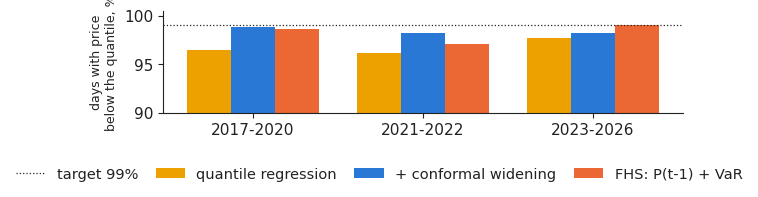

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 2.0))
ww = 0.26
for j, (k, lab, c) in enumerate([('qr', 'quantile regression', PAL['BG']), ('cqr', '+ conformal widening', PAL['RO']),
                                  ('fhs', 'FHS: P(t-1) + VaR', PAL['DE_LU'])]):
    ax.bar(np.arange(3) + (j - 1) * ww, [GUAR['a99'][k]['cov_' + p[0]] for p in PERIODS], width=ww, color=c, label=lab)
ax.axhline(99, color='#222222', lw=0.9, ls=':', label='target 99%')
ax.set_xticks(range(3))
ax.set_xticklabels(['2017-2020', '2021-2022', '2023-' + str(END.year)])
ax.set_ylim(90, 100.5)
ax.set_ylabel('days with price\nbelow the quantile, %', fontsize=9)
legend_bottom(fig, ncol=4)
fig.tight_layout(rect=(0, 0.2, 1, 1))
plt.savefig('coverage.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()